# One-branch vs two-branch MoE (Impala, phase order `variant`)

So sánh đúng hai run, cùng dữ liệu, cùng giao thức, cùng bộ nhớ (reservoir 10k), cùng seed 42, cùng thứ tự phase:

| Nhãn trên hình | Run | Kiến trúc |
|---|---|---|
| **One-branch MoE (ID-routed)** | `save/ablation_final/impala/std_moe_s42` | Router và expert đọc đặc trưng node + CAN-ID embedding; expert cũ đóng băng |
| **Two-branch MoE (behavior)** | `save/ablation_final/impala/dual_s42` | Nhánh danh tính (ID) + nhánh hành vi (expert không thấy ID, null expert); expert cũ đóng băng |

Mọi nhãn trên hình bằng tiếng Anh; hình lưu ở `figures/one_vs_two/` (PDF và PNG). Chạy từ thư mục gốc dự án; không cần GPU, trừ hai lệnh tùy chọn ở phần 6 và 7.

In [7]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path(".")
SAVE = ROOT / "../save"
FIG = ROOT / "figures/one_vs_two"
FIG.mkdir(parents=True, exist_ok=True)

ONE = "One-branch MoE (ID-routed)"
TWO = "Two-branch MoE (behavior)"
RUN_DIRS = {ONE: SAVE / "ablation_final/impala/std_moe_s42",
            TWO: SAVE / "memory/impala/mem_reservoir_10k"}
COLOR = {ONE: "#8c8c8c", TWO: "#d62728"}
SHORT = {ONE: "One-branch", TWO: "Two-branch"}

CLASS_NAMES = ["normal", "dos", "fuzzing", "gear", "interval", "rpm", "speed",
               "standstill", "systematic", "combined"]
ATTACKS = CLASS_NAMES[1:]
PHASES = ["phase1", "phase2", "phase3", "phase4", "phase5"]
PHASE_LABEL = ["P1\nbase", "P2\n+speed", "P3\nDoS variant", "P4\n+standstill", "P5\n+systematic\n+combined"]

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight"})

def savefig(name):
    plt.savefig(FIG / f"{name}.pdf"); plt.savefig(FIG / f"{name}.png", dpi=200)

def load_run(d):
    r = {"dir": d, "results": json.load(open(d / "results.json"))}
    r["cl"] = json.load(open(d / "cl_summary.json")) if (d / "cl_summary.json").exists() else {}
    r["by_phase"] = {x["phase"]: x for x in r["results"]}
    return r

def load_preds(d, phase="phase5"):
    p = Path(d) / f"preds_{phase}.npz"
    return dict(np.load(p)) if p.exists() else None

RUNS = {lab: load_run(d) for lab, d in RUN_DIRS.items()}
for lab, d in RUN_DIRS.items():
    print(f"{lab:<28} {d}")

One-branch MoE (ID-routed)   ../save/ablation_final/impala/std_moe_s42
Two-branch MoE (behavior)    ../save/memory/impala/mem_reservoir_10k


## 0. Kiểm tra tập test

Hai run phải có cùng số window mỗi lớp ở phase 5.

In [8]:
P = {lab: load_preds(d) for lab, d in RUN_DIRS.items()}
check = pd.DataFrame({lab: np.bincount(p["y"], minlength=len(CLASS_NAMES)) for lab, p in P.items()},
                     index=CLASS_NAMES).T
check["total"] = check.sum(1)
display(check)
print("Same test set." if (check.nunique() == 1).all() else "WARNING: test sets differ.")

,normal,dos,fuzzing,gear,interval,rpm,speed,standstill,systematic,combined,total
One-branch MoE (ID-routed),18000,1112,1925,657,1089,947,1414,505,909,1875,28433
Two-branch MoE (behavior),18000,1112,1925,657,1089,947,1414,505,909,1875,28433


Same test set.


## 1. Tổng hợp (phase 5)

,Macro F1,Normal FPR,Detection rate,Forgetting (mean),Forgetting (max),New-class F1 when learned,Experts
Model,,,,,,,
One-branch MoE (ID-routed),0.9755,0.0069,0.9765,0.0093,0.0219,0.9645,7
Two-branch MoE (behavior),0.9861,0.0064,0.9848,0.0051,0.0154,0.9792,7


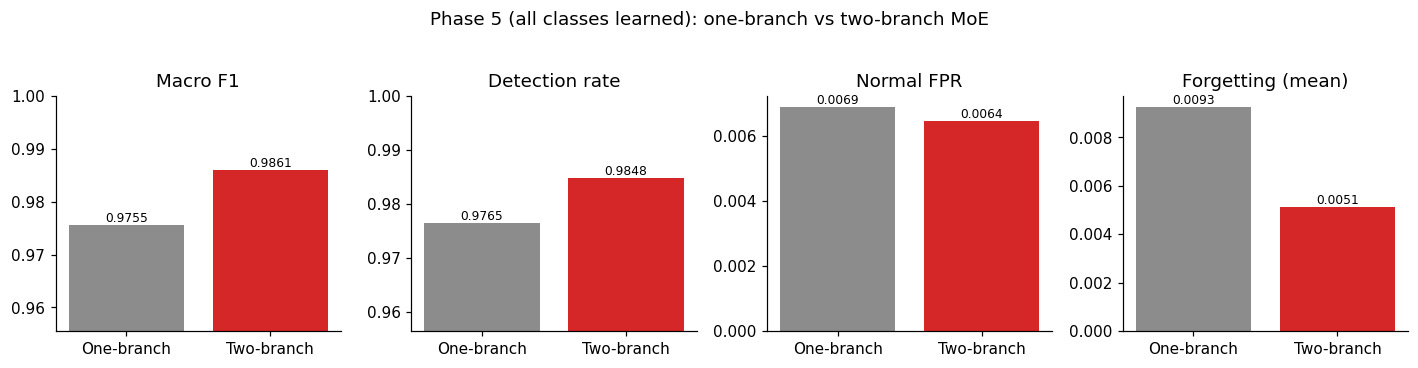

In [9]:
rows = []
for lab, r in RUNS.items():
    last = r["results"][-1]
    rows.append({"Model": lab, "Macro F1": last["overall"]["macro_f1"],
                 "Normal FPR": last["overall"]["normal_fpr"],
                 "Detection rate": last["overall"]["detection_rate"],
                 "Forgetting (mean)": r["cl"].get("forgetting_mean"),
                 "Forgetting (max)": r["cl"].get("forgetting_max"),
                 "New-class F1 when learned": r["cl"].get("new_class_f1_when_learned"),
                 "Experts": last.get("num_experts")})
summary = pd.DataFrame(rows).set_index("Model")
display(summary.round(4))

metrics = ["Macro F1", "Detection rate", "Normal FPR", "Forgetting (mean)"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, m in zip(axes, metrics):
    v = summary[m]
    bars = ax.bar([SHORT[l] for l in v.index], v.values, color=[COLOR[l] for l in v.index])
    for b, val in zip(bars, v.values):
        ax.text(b.get_x() + b.get_width() / 2, val, f"{val:.4f}", ha="center", va="bottom", fontsize=8)
    ax.set_title(m)
    if m in ("Macro F1", "Detection rate"):
        ax.set_ylim(max(0.9, v.min() - 0.02), 1.0)
fig.suptitle("Phase 5 (all classes learned): one-branch vs two-branch MoE", y=1.03)
fig.tight_layout(); savefig("fig1_summary"); plt.show()

## 2. Quỹ đạo theo phase

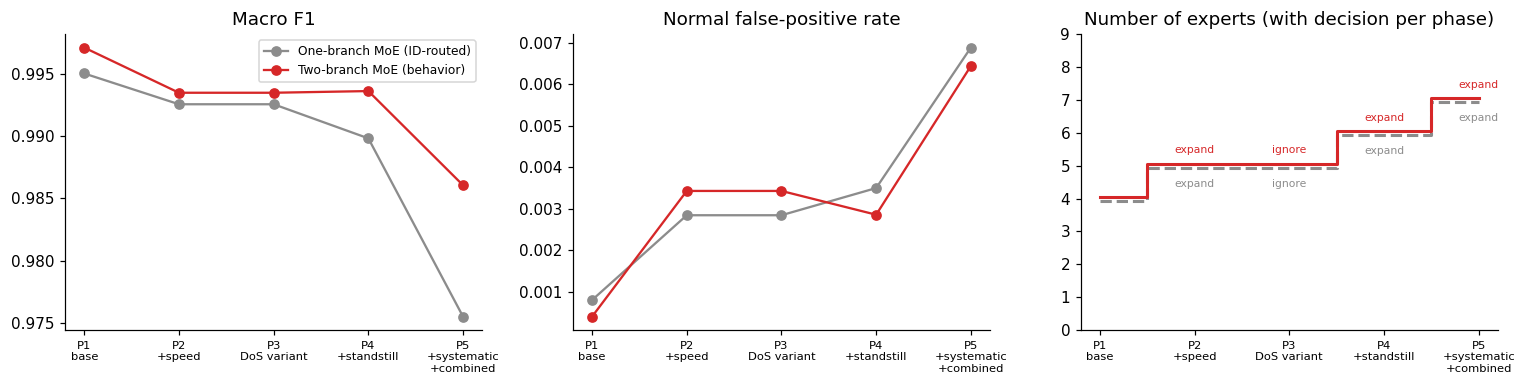

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for lab, r in RUNS.items():
    f1 = [r["by_phase"][p]["overall"]["macro_f1"] for p in PHASES]
    fpr = [r["by_phase"][p]["overall"]["normal_fpr"] for p in PHASES]
    ne = [r["by_phase"][p].get("num_experts", np.nan) for p in PHASES]
    axes[0].plot(range(5), f1, "o-", color=COLOR[lab], label=lab)
    axes[1].plot(range(5), fpr, "o-", color=COLOR[lab], label=lab)
    off = 0.06 if lab == TWO else -0.06          # small offset so equal counts stay visible
    axes[2].step(range(5), np.array(ne, float) + off, where="mid", color=COLOR[lab], label=lab, lw=2,
                 ls="-" if lab == TWO else "--")
    for i, p in enumerate(PHASES[1:], start=1):
        d = r["by_phase"][p].get("decision_info", {}).get("decision", "")
        axes[2].annotate(d, (i, ne[i]), textcoords="offset points",
                         xytext=(0, 8 if lab == TWO else -14), ha="center", fontsize=7, color=COLOR[lab])
for ax, t in zip(axes, ("Macro F1", "Normal false-positive rate", "Number of experts (with decision per phase)")):
    ax.set_xticks(range(5)); ax.set_xticklabels(PHASE_LABEL, fontsize=7.5); ax.set_title(t)
axes[2].set_ylim(0, 9)
axes[0].legend(fontsize=8)
fig.tight_layout(); savefig("fig2_trajectory"); plt.show()

## 3. F1 từng lớp

,One-branch MoE (ID-routed),Two-branch MoE (behavior),Δ (two − one)
normal,0.9898,0.9924,0.0026
dos,0.9987,0.9986,-0.0000
fuzzing,0.9674,0.9909,0.0235
gear,0.9863,0.9839,-0.0024
interval,0.9908,0.9940,0.0032
rpm,0.9815,0.9910,0.0095
speed,0.9736,0.9806,0.0070
standstill,0.9749,0.9910,0.0162
systematic,0.9471,0.9857,0.0386
combined,0.9451,0.9525,0.0075


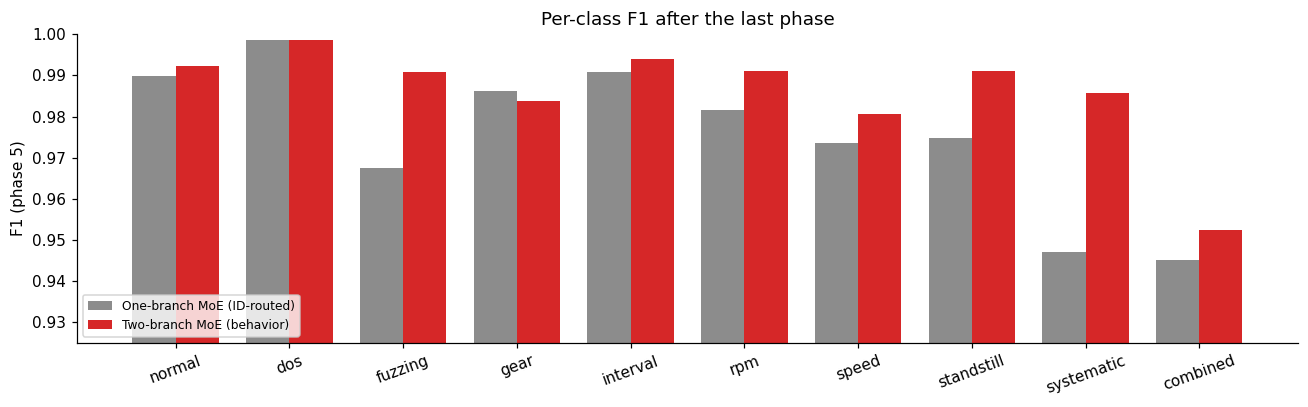

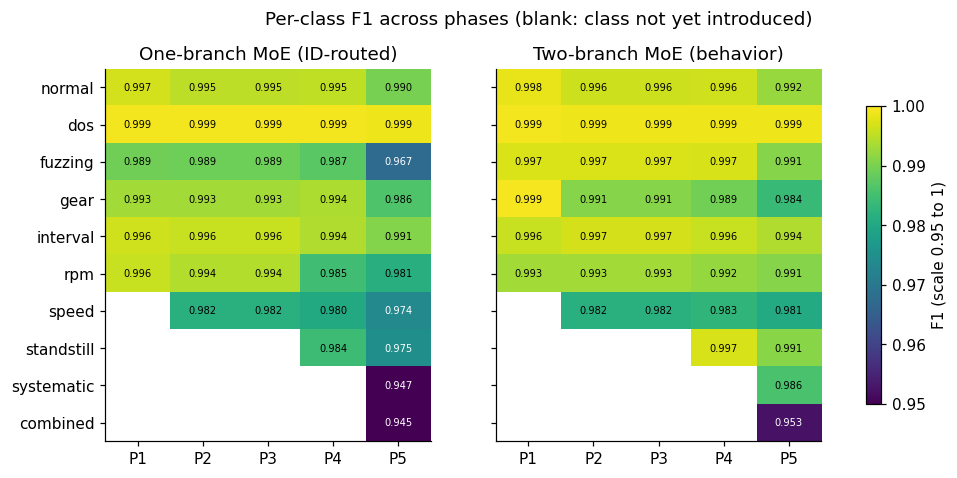

In [11]:
pc = pd.DataFrame({lab: [r["results"][-1]["per_attack"].get(c, np.nan) for c in CLASS_NAMES]
                   for lab, r in RUNS.items()}, index=CLASS_NAMES)
pc["Δ (two − one)"] = pc[TWO] - pc[ONE]
display(pc.round(4))

fig, ax = plt.subplots(figsize=(12, 3.8))
x = np.arange(len(CLASS_NAMES)); w = 0.38
for i, lab in enumerate((ONE, TWO)):
    ax.bar(x + (i - 0.5) * w, pc[lab], w, color=COLOR[lab], label=lab)
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES, rotation=20)
ax.set_ylim(max(0.85, pc[[ONE, TWO]].min().min() - 0.02), 1.0)
ax.set_ylabel("F1 (phase 5)"); ax.set_title("Per-class F1 after the last phase")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout(); savefig("fig3_per_class_f1"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), sharey=True)
for ax, (lab, r) in zip(axes, RUNS.items()):
    M = np.full((len(CLASS_NAMES), 5), np.nan)
    for j, p in enumerate(PHASES):
        for i, c in enumerate(CLASS_NAMES):
            v = r["by_phase"][p]["per_attack"].get(c, 0)
            if v > 0:
                M[i, j] = v
    im = ax.imshow(M, vmin=0.95, vmax=1, cmap="viridis", aspect="auto")
    for i in range(M.shape[0]):
        for j in range(5):
            if np.isfinite(M[i, j]):
                ax.text(j, i, f"{M[i, j]:.3f}", ha="center", va="center", fontsize=6.5,
                        color="white" if M[i, j] < 0.975 else "black")
    ax.set_xticks(range(5)); ax.set_xticklabels([f"P{k}" for k in range(1, 6)])
    ax.set_yticks(range(len(CLASS_NAMES))); ax.set_yticklabels(CLASS_NAMES); ax.set_title(lab)
fig.colorbar(im, ax=axes.tolist(), shrink=0.8, label="F1 (scale 0.95 to 1)")
fig.suptitle("Per-class F1 across phases (blank: class not yet introduced)", y=1.0)
savefig("fig3b_per_class_f1_phases"); plt.show()

## 4. Quên theo lớp

Forgetting của mỗi lớp = F1 tốt nhất ở các phase trước trừ F1 ở phase 5.

,One-branch MoE (ID-routed),Two-branch MoE (behavior)
normal,0.0069,0.0059
dos,0.0004,0.0005
fuzzing,0.0219,0.0062
gear,0.0076,0.0154
interval,0.0055,0.0028
rpm,0.0143,0.0021
speed,0.0081,0.0022
standstill,0.0094,0.0060


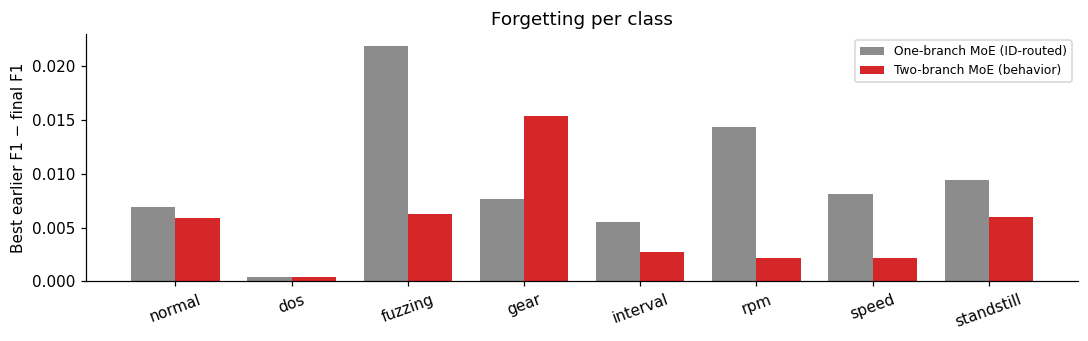

In [12]:
rows = {}
for lab, r in RUNS.items():
    fg = {}
    for c in CLASS_NAMES:
        hist = [r["by_phase"][p]["per_attack"].get(c, 0) for p in PHASES]
        prev = [v for v in hist[:-1] if v > 0]
        if prev:
            fg[c] = max(prev) - hist[-1]
    rows[lab] = fg
fgt = pd.DataFrame(rows)
display(fgt.round(4))
fig, ax = plt.subplots(figsize=(10, 3.2))
x = np.arange(len(fgt)); w = 0.38
for i, lab in enumerate((ONE, TWO)):
    ax.bar(x + (i - 0.5) * w, fgt[lab], w, color=COLOR[lab], label=lab)
ax.axhline(0, color="black", lw=0.6)
ax.set_xticks(x); ax.set_xticklabels(fgt.index, rotation=20)
ax.set_ylabel("Best earlier F1 − final F1"); ax.set_title("Forgetting per class")
ax.legend(fontsize=8)
fig.tight_layout(); savefig("fig4_forgetting"); plt.show()

## 5. Lỗi: ma trận nhầm lẫn và các cặp khó (phase 5)

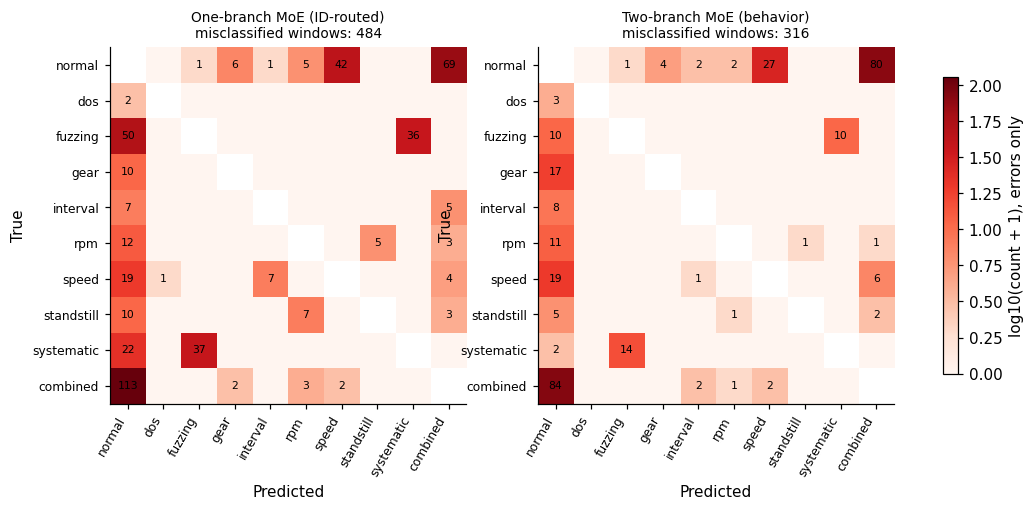

,One-branch MoE (ID-routed),Two-branch MoE (behavior)
fuzzing → systematic,36,10
systematic → fuzzing,37,14
combined → normal,113,84
normal → combined,69,80
speed → normal,19,19
normal → speed,42,27
standstill → rpm,7,1
rpm → standstill,5,1
false alarms (normal → any attack),124,116
missed attacks (attack → normal),245,159


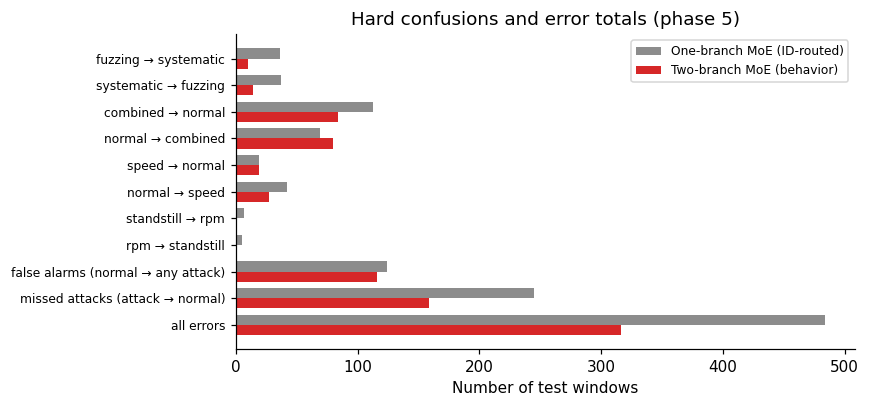

In [13]:
def confusion(p):
    y, yh = p["y"], p["logits"].astype(np.float32).argmax(1)
    K = len(CLASS_NAMES); cm = np.zeros((K, K), int); np.add.at(cm, (y, yh), 1)
    return cm

CM = {lab: confusion(p) for lab, p in P.items()}
vmax = max(np.log10(cm[~np.eye(len(CLASS_NAMES), dtype=bool)].max() + 1) for cm in CM.values())
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5))
for ax, (lab, cm) in zip(axes, CM.items()):
    off = cm.astype(float); np.fill_diagonal(off, np.nan)
    im = ax.imshow(np.log10(off + 1), cmap="Reds", vmin=0, vmax=vmax)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if i != j and cm[i, j] > 0:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7)
    ax.set_xticks(range(len(CLASS_NAMES))); ax.set_xticklabels(CLASS_NAMES, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(CLASS_NAMES))); ax.set_yticklabels(CLASS_NAMES, fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(f"{lab}\nmisclassified windows: {int(cm.sum() - np.trace(cm))}", fontsize=9)
fig.colorbar(im, ax=axes.tolist(), shrink=0.7, label="log10(count + 1), errors only")
savefig("fig5_confusion"); plt.show()

ix = {c: i for i, c in enumerate(CLASS_NAMES)}
pairs = [("fuzzing", "systematic"), ("systematic", "fuzzing"), ("combined", "normal"),
         ("normal", "combined"), ("speed", "normal"), ("normal", "speed"),
         ("standstill", "rpm"), ("rpm", "standstill")]
hard = pd.DataFrame({lab: [cm[ix[a], ix[b]] for a, b in pairs] for lab, cm in CM.items()},
                    index=[f"{a} → {b}" for a, b in pairs])
hard.loc["false alarms (normal → any attack)"] = {lab: int(cm[0, 1:].sum()) for lab, cm in CM.items()}
hard.loc["missed attacks (attack → normal)"] = {lab: int(cm[1:, 0].sum()) for lab, cm in CM.items()}
hard.loc["all errors"] = {lab: int(cm.sum() - np.trace(cm)) for lab, cm in CM.items()}
display(hard)

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(hard)); h = 0.38
for i, lab in enumerate((ONE, TWO)):
    ax.barh(y + (i - 0.5) * h, hard[lab], h, color=COLOR[lab], label=lab)
ax.set_yticks(y); ax.set_yticklabels(hard.index, fontsize=8); ax.invert_yaxis()
ax.set_xlabel("Number of test windows"); ax.set_title("Hard confusions and error totals (phase 5)")
ax.legend(fontsize=8)
fig.tight_layout(); savefig("fig5b_hard_pairs"); plt.show()

## 6. Chuyên môn hóa của expert

Mô hình một nhánh không lưu routing theo node trong `preds_*.npz`, nên route heatmap chỉ vẽ được cho mô hình hai nhánh; NMI lấy từ `results.json` nếu có.

Để so sánh **mức phụ thuộc vào CAN ID** trên đúng hai run này (tùy chọn, vài phút, cần GPU):

```bash
python -u diag_two_branch.py --run save/ablation_final/impala/std_moe_s42 --out save/v3/diag/cmp_std_moe_s42.json
python -u diag_two_branch.py --run save/ablation_final/impala/dual_s42    --out save/v3/diag/cmp_dual_s42.json
```

,Model,Phase,"NMI(expert, class)","NMI(expert, CAN ID)",Attacked nodes → null
0,Two-branch MoE (behavior),phase1,0.467,0.134,0.010
1,Two-branch MoE (behavior),phase2,0.501,0.166,0.011
2,Two-branch MoE (behavior),phase3,0.501,0.166,0.011
3,Two-branch MoE (behavior),phase4,0.502,0.171,0.010
4,Two-branch MoE (behavior),phase5,0.432,0.184,0.037


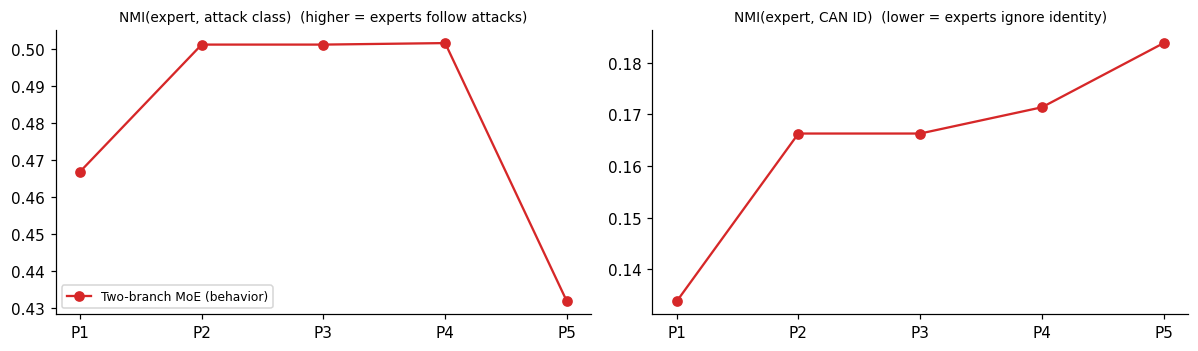

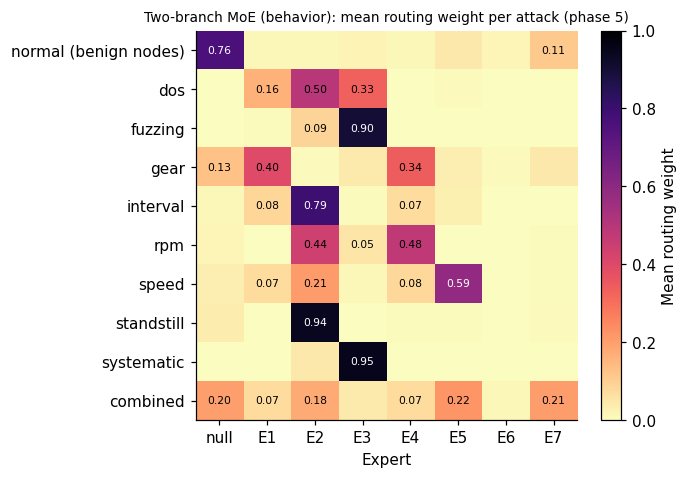

Run the two diag commands above to add the CAN-ID reliance figure.


In [14]:
rows = []
for lab, r in RUNS.items():
    for x in r["results"]:
        s = x.get("specialization") or {}
        if s:
            rows.append({"Model": lab, "Phase": x["phase"],
                         "NMI(expert, class)": s.get("nmi_active_class"),
                         "NMI(expert, CAN ID)": s.get("nmi_active_canid"),
                         "Attacked nodes → null": s.get("null_rate_attacked_nodes")})
spec = pd.DataFrame(rows)
if len(spec):
    display(spec.round(3))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
    for lab in spec.Model.unique():
        d = spec[spec.Model == lab].set_index("Phase").reindex(PHASES)
        axes[0].plot(range(5), d["NMI(expert, class)"], "o-", color=COLOR[lab], label=lab)
        axes[1].plot(range(5), d["NMI(expert, CAN ID)"], "o-", color=COLOR[lab], label=lab)
    for ax, t in zip(axes, ("NMI(expert, attack class)  (higher = experts follow attacks)",
                            "NMI(expert, CAN ID)  (lower = experts ignore identity)")):
        ax.set_xticks(range(5)); ax.set_xticklabels([f"P{k}" for k in range(1, 6)]); ax.set_title(t, fontsize=9)
    axes[0].legend(fontsize=8); fig.tight_layout(); savefig("fig6_specialization"); plt.show()

p2 = P[TWO]
if p2 is not None and "node_probs" in p2:
    atk, ny, pr = p2["node_atk"] > 0, p2["node_ny"], p2["node_probs"].astype(np.float32)
    rows, labs = [pr[~atk].mean(0)], ["normal (benign nodes)"]
    for c in range(1, len(CLASS_NAMES)):
        s = atk & (ny == c)
        if s.sum() >= 20:
            rows.append(pr[s].mean(0)); labs.append(CLASS_NAMES[c])
    M = np.vstack(rows)
    fig, ax = plt.subplots(figsize=(5.6, 4.6))
    im = ax.imshow(M, vmin=0, vmax=1, cmap="magma_r", aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if M[i, j] >= 0.05:
                ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if M[i, j] > 0.55 else "black")
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(["null"] + [f"E{k}" for k in range(1, M.shape[1])])
    ax.set_yticks(range(len(labs))); ax.set_yticklabels(labs)
    ax.set_xlabel("Expert"); ax.set_title(f"{TWO}: mean routing weight per attack (phase 5)", fontsize=9)
    plt.colorbar(im, ax=ax, label="Mean routing weight")
    savefig("fig6b_route_heatmap_two_branch"); plt.show()

diag = {}
for lab, f in ((ONE, "cmp_std_moe_s42"), (TWO, "cmp_dual_s42")):
    fp = SAVE / "v3/diag" / f"{f}.json"
    if fp.exists():
        d = json.load(open(fp))
        diag[lab] = {"Intact": d["baseline"]["macro_f1"],
                     "CAN IDs permuted": d["C_id_reliance"]["permuted_ids"]["macro_f1"],
                     "All CAN IDs masked": d["C_id_reliance"]["all_ids_padding"]["macro_f1"]}
if len(diag) == 2:
    dg = pd.DataFrame(diag).T
    display(dg.round(4))
    ax = dg.T.plot.bar(figsize=(7, 3.3), rot=0, color=[COLOR[l] for l in dg.index])
    ax.set_ylim(0, 1); ax.set_ylabel("Macro F1"); ax.set_title("Reliance on CAN-ID identity")
    ax.legend(fontsize=8); savefig("fig6c_id_reliance"); plt.show()
else:
    print("Run the two diag commands above to add the CAN-ID reliance figure.")

## 7. Chuyển xe Impala → Traverse (tùy chọn)

Đánh giá cả hai run trên Traverse mà không huấn luyện lại (vài phút, cần GPU):

```bash
python -u cross_eval.py --target_data ./data/2011-chevrolet-traverse/preprocessed_window_cal \
    --runs save/ablation_final/impala/std_moe_s42 save/ablation_final/impala/dual_s42 \
    --out save/cross_vehicle/one_vs_two_branch
```

In [ ]:
f = SAVE / "cross_vehicle/one_vs_two_branch/cross_eval.json"
if f.exists():
    name_to_lab = {"std_moe_s42": ONE, "dual_s42": TWO}
    rows = {name_to_lab.get(r["run"], r["run"]): r for r in json.load(open(f))}
    cv = pd.DataFrame({lab: {"10-class macro F1": r["macro_f1"], "Binary g-mean": r["bin_gmean"],
                             "Normal FPR": r["normal_fpr"], "Detection (TPR)": r["bin_tpr"]}
                       for lab, r in rows.items()}).T
    display(cv.round(4))
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
    for ax, m in zip(axes, ("10-class macro F1", "Binary g-mean", "Normal FPR")):
        v = cv[m]
        bars = ax.bar([SHORT[l] for l in v.index], v.values, color=[COLOR[l] for l in v.index])
        for b, val in zip(bars, v.values):
            ax.text(b.get_x() + b.get_width() / 2, val, f"{val:.3f}", ha="center", va="bottom", fontsize=8)
        ax.set_title(m)
    fig.suptitle("Impala → Traverse without retraining (normal-traffic calibration only)", y=1.03)
    fig.tight_layout(); savefig("fig7_cross_vehicle"); plt.show()
    pa = pd.DataFrame({lab: [r.get(f"f1_{a}") for a in ATTACKS] for lab, r in rows.items()}, index=ATTACKS)
    ax = pa.plot.bar(figsize=(10, 3.2), rot=20, color=[COLOR[l] for l in pa.columns])
    ax.set_ylabel("F1 on Traverse"); ax.set_title("Per-attack transfer"); ax.legend(fontsize=8)
    savefig("fig7b_cross_vehicle_per_attack"); plt.show()
else:
    print("Run the cross_eval command above to add the cross-vehicle figures.")

## 8. Xuất bảng

In [ ]:
summary.to_csv(FIG / "summary.csv"); pc.to_csv(FIG / "per_class_f1.csv")
hard.to_csv(FIG / "hard_pairs.csv"); fgt.to_csv(FIG / "forgetting_per_class.csv")
cols = ["Macro F1", "Normal FPR", "Detection rate", "Forgetting (mean)", "Experts"]
lines = ["\\begin{tabular}{l" + "r" * len(cols) + "}", "\\toprule", "Model & " + " & ".join(cols) + " \\\\", "\\midrule"]
for lab, r in summary[cols].iterrows():
    vals = [f"{v:.4f}" if isinstance(v, float) and v < 1.5 else f"{int(v)}" for v in r.values]
    lines.append(f"{lab} & " + " & ".join(vals) + " \\\\")
lines += ["\\bottomrule", "\\end{tabular}"]
(FIG / "summary.tex").write_text("\n".join(lines))
print("Saved to", FIG.resolve())